# 03 - Analysis

KPIs, monthly trend, countries and products, cohort retention, RFM segmentation and a simple LTV.
Reusable logic lives in `src/analysis.py`.

**Scope rules**
- Products only (`is_product == True`) for every analysis. Postage, fees, manual entries and vouchers are excluded.
- December 2011 (`is_partial_month`, data ends on the 9th) is excluded from monthly trends and cohorts, but kept in all-time totals.
- Revenue is in GBP. Net = sales + cancellations (cancellations are negative). Gross = non-cancelled rows only.
- `Description` is standardised per StockCode (most frequent text) and is used for display only.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import FuncFormatter, PercentFormatter

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src import analysis as an
from src.clean_data import CLEAN_PATH, CUSTOMER_PATH

an.apply_style()
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:,.1f}".format)

TABLE_DIR = ROOT / "reports" / "tables"
TABLE_DIR.mkdir(parents=True, exist_ok=True)
saved: list[Path] = []

In [2]:
clean = pd.read_parquet(CLEAN_PATH)
df = an.products_only(clean)                        # all-time product rows (incl. Dec 2011)
cust = pd.read_parquet(CUSTOMER_PATH)               # has_customer & is_product already
full = df[~df["is_partial_month"]]                  # for monthly trends
print(f"transactions_clean: {len(clean):,} rows -> products: {len(df):,} rows")
print(f"customer_transactions: {len(cust):,} rows, {cust['Customer ID'].nunique():,} customers")

transactions_clean: 1,027,016 rows -> products: 1,021,272 rows
customer_transactions: 794,183 rows, 5,875 customers


## 1. KPIs

- **Orders** = distinct non-cancelled invoices, **excluding fully cancelled orders**. An order is fully cancelled when every line was later reversed by a "C" invoice from the same customer, with the same StockCode and the same quantity. Matching is one-to-one, and the cancellation must be dated at or after the purchase.
- **AOV** = gross revenue of those orders / orders.
- **Gross revenue, cancellations and the cancellation rate** still include every row, so the fully cancelled orders appear in gross revenue and are offset in cancellations.
- **Customers** = distinct Customer IDs with at least one purchase.
- **Year coverage:** 2009 is December only and 2011 ends on 9 December, so years are not directly comparable.

In [3]:
fully_cancelled = an.fully_cancelled_invoices(df)
fc_rows = df[df["Invoice"].isin(fully_cancelled)]
print(f"Fully cancelled orders: {len(fully_cancelled):,} invoices, {len(fc_rows):,} lines, "
      f"£{fc_rows['line_revenue'].sum():,.0f} gross revenue")
print("Includes the two bulk orders:", {"541431", "581483"} <= fully_cancelled)

kpi = pd.concat([an.kpis(df, exclude_orders=fully_cancelled),
                 an.kpis(df, by=df["InvoiceDate"].dt.year.rename("period"), exclude_orders=fully_cancelled)])
kpi.index = kpi.index.astype(str)
kpi.to_csv(TABLE_DIR / "kpis.csv"); saved.append(TABLE_DIR / "kpis.csv")
kpi

Fully cancelled orders: 270 invoices, 1,913 lines, £440,527 gross revenue
Includes the two bulk orders: True


,net_revenue,gross_revenue,cancellations,cancellation_rate_pct,orders,fully_cancelled_orders,customers,avg_order_value
period,,,,,,,,
All time,"18,927,399.1","19,643,861.6","-716,462.6",3.6,39246,270,5852,489.3
2009,"778,343.1","797,901.2","-19,558.1",2.5,1659,7,951,479.7
2010,"9,135,828.3","9,374,379.5","-238,551.2",2.5,19482,145,4205,477.1
2011,"9,013,227.7","9,471,581.0","-458,353.3",4.8,18105,118,4214,503.4


### Note: two cancellation rates

The cleaning log reports a cancellation rate of **7.1%**, measured over **all codes**. This notebook reports **3.6%**, measured over **products only**.
The difference comes from the non-product codes. They are only about 4% of gross revenue (£0.82M of £20.47M), but they carry about half of all cancellation value (£0.75M of £1.46M).
Most of it is accounting entries rather than returned goods: manual adjustments (`M`, about £423K) and Amazon fees (`AMAZONFEE`, about £242K).
The product rate of 3.6% is the one that describes customer returns.

In [4]:
def cancel_rate(d: pd.DataFrame) -> pd.Series:
    gross = d.loc[~d["is_cancelled"], "line_revenue"].sum()
    canc = d.loc[d["is_cancelled"], "line_revenue"].sum()
    return pd.Series({"gross_revenue": gross, "cancellations": canc, "cancellation_rate_pct": -canc / gross * 100})

rates = pd.DataFrame({
    "All codes (cleaning log)": cancel_rate(clean),
    "Products only (this notebook)": cancel_rate(clean[clean["is_product"]]),
    "Non-product codes": cancel_rate(clean[~clean["is_product"]]),
}).T
display(rates)
np_cancel = (clean[clean["is_cancelled"] & ~clean["is_product"]].groupby("StockCode")["line_revenue"]
             .sum().sort_values().head(6).rename("cancellations_gbp"))
np_cancel.to_frame()

,gross_revenue,cancellations,cancellation_rate_pct
All codes (cleaning log),"20,465,198.4","-1,462,050.6",7.1
Products only (this notebook),"19,643,861.6","-716,462.6",3.6
Non-product codes,"821,336.8","-745,588.0",90.8


,cancellations_gbp
StockCode,
M,"-422,552.6"
AMAZONFEE,"-241,988.3"
BANK CHARGES,"-36,001.5"
POST,"-15,252.0"
D,"-13,277.5"
CRUK,"-7,933.4"


### Like-for-like check: January to November

Orders and AOV exclude fully cancelled orders, as above.
For cancellations, the two one-off bulk orders of 80,995 and 74,215 units were cancelled within minutes, both in 2011.
They add about £245K to both gross revenue and cancellations, so the cancellation rate is also shown without them.

In [5]:
bulk = an.bulk_order_invoices(df)
print("Bulk order invoices:", bulk)
jan_nov = df[df["InvoiceDate"].dt.month <= 11]
year = jan_nov["InvoiceDate"].dt.year.rename("year")
no_bulk = ~jan_nov["Invoice"].isin(bulk)
lfl = pd.concat({
    "Jan-Nov": an.kpis(jan_nov, by=year, exclude_orders=fully_cancelled),
    "Jan-Nov, excl. bulk orders": an.kpis(jan_nov[no_bulk], by=year[no_bulk], exclude_orders=fully_cancelled),
}).loc[(slice(None), [2010, 2011]), :]
growth = lfl.xs(2011, level=1) / lfl.xs(2010, level=1) * 100 - 100
display(lfl)
print("2011 vs 2010, % change:")
growth[["net_revenue", "gross_revenue", "orders", "customers", "avg_order_value"]]

Bulk order invoices: ['541431', '581483', 'C541433', 'C581484']


net_revenue  gross_revenue  cancellations  cancellation_rate_pct  orders  fully_cancelled_orders  customers  avg_order_value
                           year                                                                                                                              
Jan-Nov                    2010  8,377,737.8    8,598,741.2     -221,003.3                    2.6   17940                     137       4127            475.1
                           2011  8,572,828.1    8,857,090.0     -284,261.9                    3.2   17294                     113       4168            501.2
Jan-Nov, excl. bulk orders 2010  8,377,737.8    8,598,741.2     -221,003.3                    2.6   17940                     137       4127            475.1
                           2011  8,572,828.1    8,779,906.4     -207,078.3                    2.4   17294                     112       4167            501.2

2011 vs 2010, % change:


,net_revenue,gross_revenue,orders,customers,avg_order_value
Jan-Nov,2.3,3.0,-3.6,1.0,5.5
"Jan-Nov, excl. bulk orders",2.3,2.1,-3.6,1.0,5.5


## 2. Monthly trend (December 2011 excluded)

In [6]:
monthly = an.monthly_kpis(df, exclude_orders=fully_cancelled)   # includes the partial month, flagged
trend = monthly[~monthly["is_partial_month"]]
trend[["month", "net_revenue", "gross_revenue", "mom_growth_pct", "orders", "customers", "avg_order_value"]]

,month,net_revenue,gross_revenue,mom_growth_pct,orders,customers,avg_order_value
0,2009-12-01,"778,343.1","797,901.2",NaN,1659,951,479.7
1,2010-01-01,"604,831.8","612,297.4",-22.3,1040,701,587.3
2,2010-02-01,"525,334.2","537,909.7",-13.1,1177,771,454.9
3,2010-03-01,"752,102.1","761,706.0",43.2,1635,1051,464.9
4,2010-04-01,"636,315.7","646,340.9",-15.4,1428,939,451.5
5,2010-05-01,"606,299.1","643,492.0",-4.7,1473,965,427.8
6,2010-06-01,"670,209.7","696,583.2",10.5,1604,1034,425.8
7,2010-07-01,"615,861.6","632,994.3",-8.1,1492,924,421.1
8,2010-08-01,"661,640.1","674,037.7",7.4,1394,910,480.3
9,2010-09-01,"841,556.7","869,243.1",27.2,1773,1136,487.3


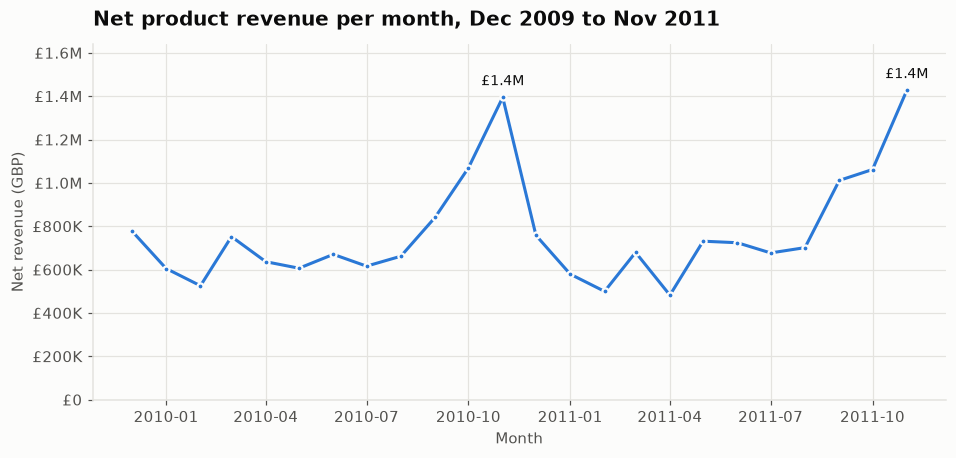

In [7]:
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.plot(trend["month"], trend["net_revenue"], color=an.BLUE, marker="o", markersize=4,
        markeredgecolor=an.SURFACE, markeredgewidth=1.5)
for _, r in trend.nlargest(2, "net_revenue").iterrows():
    ax.annotate(an.gbp(r["net_revenue"]), (r["month"], r["net_revenue"]), xytext=(0, 8),
                textcoords="offset points", ha="center", fontsize=9, color=an.INK)
ax.yaxis.set_major_formatter(an.GBP_FMT)
ax.set_ylim(0, trend["net_revenue"].max() * 1.15)
ax.set_title("Net product revenue per month, Dec 2009 to Nov 2011")
ax.set_xlabel("Month")
ax.set_ylabel("Net revenue (GBP)")
saved.append(an.save_fig(fig, "01_monthly_net_revenue"))
plt.show()

In [8]:
comp = an.calendar_month_comparison(monthly)
peak = comp[[2010, 2011]].stack().sort_values(ascending=False).head(4)
by_year = trend.assign(year=trend["month"].dt.year).groupby("year")["net_revenue"]
q4_share = (trend[trend["month"].dt.month.isin([9, 10, 11])].groupby(trend["month"].dt.year)["net_revenue"].sum()
            / trend[trend["month"].dt.month <= 11].groupby(trend["month"].dt.year)["net_revenue"].sum() * 100)
print("Top months:"); print(peak.map(an.gbp).to_string())
print("\nSep-Nov share of Jan-Nov net revenue (%):"); print(q4_share.loc[[2010, 2011]].round(1).to_string())
comp

Top months:
cal_month  year
Nov        2011    £1.4M
           2010    £1.4M
Oct        2010    £1.1M
           2011    £1.1M

Sep-Nov share of Jan-Nov net revenue (%):
month
2010   39.5
2011   40.8


year,2010,2011,yoy_growth_pct
cal_month,,,
Jan,"604,831.8","578,855.2",-4.3
Feb,"525,334.2","499,464.3",-4.9
Mar,"752,102.1","679,329.2",-9.7
Apr,"636,315.7","482,061.9",-24.2
May,"606,299.1","731,004.8",20.6
Jun,"670,209.7","723,845.1",8.0
Jul,"615,861.6","676,812.1",9.9
Aug,"661,640.1","701,289.9",6.0
Sep,"841,556.7","1,011,339.7",20.2


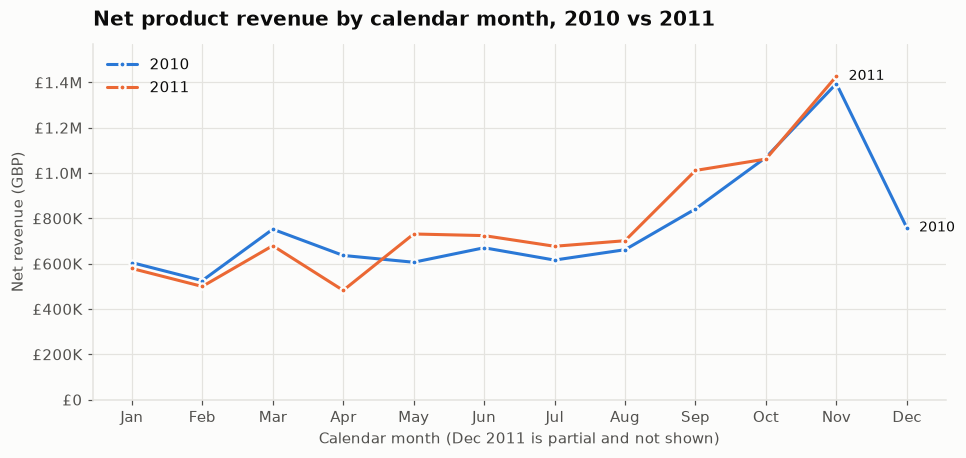

In [9]:
fig, ax = plt.subplots(figsize=(10, 4.2))
x = np.arange(len(comp))
for year, color in [(2010, an.BLUE), (2011, an.ORANGE)]:
    ax.plot(x, comp[year], color=color, marker="o", markersize=4, markeredgecolor=an.SURFACE,
            markeredgewidth=1.5, label=str(year))
    last = comp[year].last_valid_index()
    ax.annotate(str(year), (comp.index.get_loc(last), comp.loc[last, year]), xytext=(8, 0),
                textcoords="offset points", va="center", fontsize=9, color=an.INK)
ax.set_xticks(x, comp.index)
ax.yaxis.set_major_formatter(an.GBP_FMT)
ax.set_ylim(0, comp[[2010, 2011]].max().max() * 1.1)
ax.set_title("Net product revenue by calendar month, 2010 vs 2011")
ax.set_xlabel("Calendar month (Dec 2011 is partial and not shown)")
ax.set_ylabel("Net revenue (GBP)")
ax.legend(loc="upper left")
saved.append(an.save_fig(fig, "02_revenue_2010_vs_2011"))
plt.show()

## 3. Countries and products (all time)

In [10]:
countries = an.top_by_revenue(df, "Country", 10)
uk_share = countries.loc["United Kingdom", "share_pct"]
print(f"UK share of net product revenue: {uk_share:.1f}%")
countries

UK share of net product revenue: 85.4%


,net_revenue,share_pct
Country,,
United Kingdom,"16,168,905.9",85.4
EIRE,"603,116.6",3.2
Netherlands,"546,095.4",2.9
Germany,"374,573.5",2.0
France,"293,431.2",1.6
Australia,"166,282.1",0.9
Switzerland,"92,918.1",0.5
Spain,"84,811.6",0.4
Sweden,"84,345.2",0.4


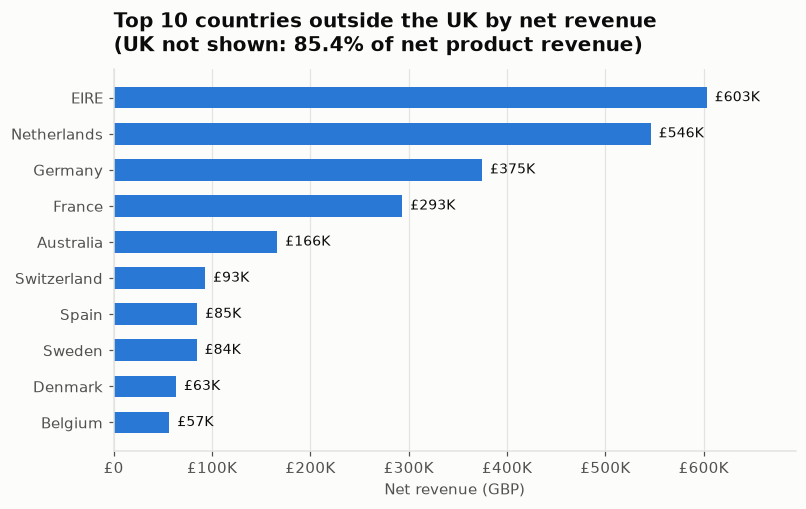

In [11]:
non_uk = an.top_by_revenue(df[df["Country"] != "United Kingdom"], "Country", 10)
non_uk["share_of_total_pct"] = non_uk["net_revenue"] / df["line_revenue"].sum() * 100
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(non_uk.index[::-1], non_uk["net_revenue"][::-1], height=0.6, color=an.BLUE)
for i, v in enumerate(non_uk["net_revenue"][::-1]):
    ax.text(v, i, f"  {an.gbp(v)}", va="center", fontsize=9, color=an.INK)
ax.xaxis.set_major_formatter(an.GBP_FMT)
ax.grid(axis="y", visible=False)
ax.set_xlim(0, non_uk["net_revenue"].max() * 1.15)
ax.set_title(f"Top 10 countries outside the UK by net revenue\n(UK not shown: {uk_share:.1f}% of net product revenue)")
ax.set_xlabel("Net revenue (GBP)")
saved.append(an.save_fig(fig, "03_top_countries_excl_uk"))
plt.show()

In [12]:
products = an.top_by_revenue(df, "StockCode", 10)
names = df.drop_duplicates("StockCode").set_index("StockCode")["Description"]
products.insert(0, "Description", products.index.map(names))
products

,Description,net_revenue,share_pct
StockCode,,,
22423,REGENCY CAKESTAND 3 TIER,"314,045.0",1.7
85123A,WHITE HANGING HEART T-LIGHT HOLDER,"251,781.6",1.3
85099B,JUMBO BAG RED RETROSPOT,"180,512.2",1.0
47566,PARTY BUNTING,"147,079.7",0.8
84879,ASSORTED COLOUR BIRD ORNAMENT,"128,550.4",0.7
22086,PAPER CHAIN KIT 50'S CHRISTMAS,"116,298.6",0.6
79321,CHILLI LIGHTS,"79,905.1",0.4
22197,SMALL POPCORN HOLDER,"78,903.6",0.4
22386,JUMBO BAG PINK POLKADOT,"75,457.6",0.4


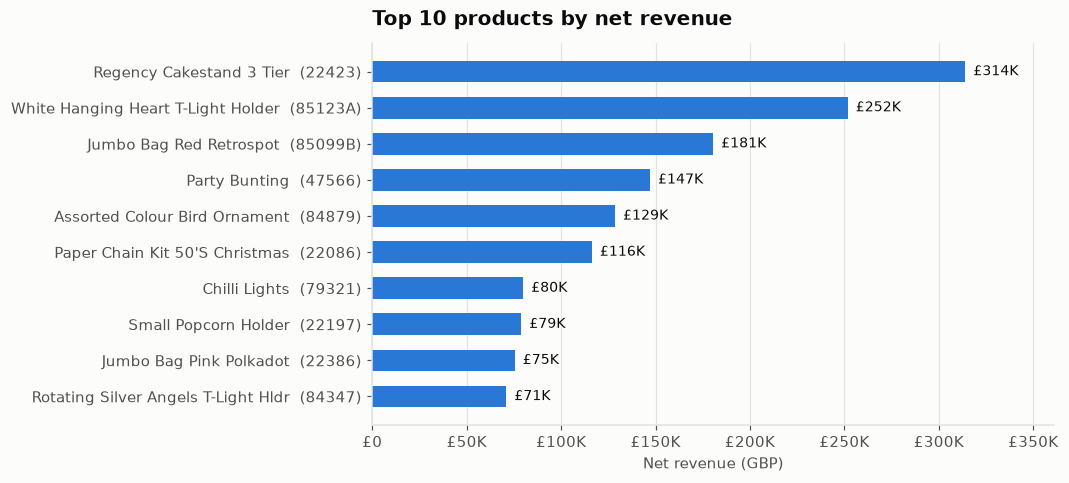

In [13]:
fig, ax = plt.subplots(figsize=(8, 4.5))
labels = (products["Description"].str.title() + "  (" + products.index + ")")[::-1]
ax.barh(labels, products["net_revenue"][::-1], height=0.6, color=an.BLUE)
for i, v in enumerate(products["net_revenue"][::-1]):
    ax.text(v, i, f"  {an.gbp(v)}", va="center", fontsize=9, color=an.INK)
ax.xaxis.set_major_formatter(an.GBP_FMT)
ax.grid(axis="y", visible=False)
ax.set_xlim(0, products["net_revenue"].max() * 1.15)
ax.set_title("Top 10 products by net revenue")
ax.set_xlabel("Net revenue (GBP)")
saved.append(an.save_fig(fig, "04_top_products"))
plt.show()

21.9% of 4,739 products make 80% of net product revenue


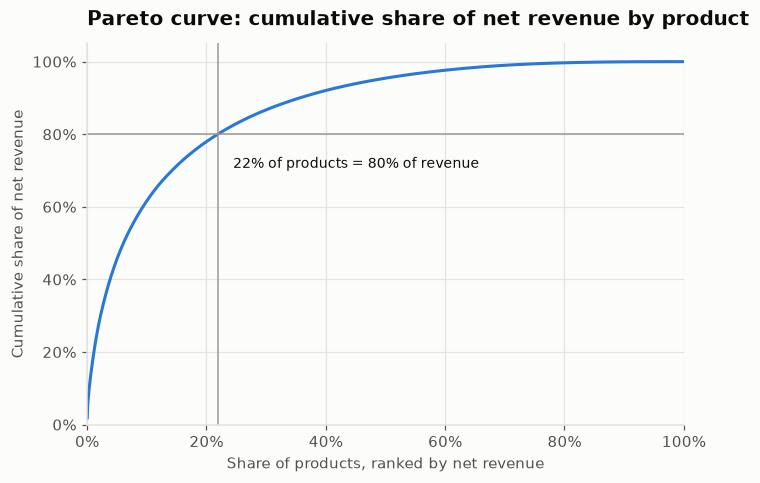

In [14]:
curve, pct_80 = an.pareto(df)
print(f"{pct_80:.1f}% of {len(curve):,} products make 80% of net product revenue")
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(curve["item_pct"], curve["cum_revenue_pct"], color=an.BLUE)
ax.axhline(80, color=an.REF_LINE, linewidth=1)
ax.axvline(pct_80, color=an.REF_LINE, linewidth=1)
ax.annotate(f"{pct_80:.0f}% of products = 80% of revenue", (pct_80, 80), xytext=(10, -22),
            textcoords="offset points", fontsize=9, color=an.INK)
ax.xaxis.set_major_formatter(PercentFormatter())
ax.yaxis.set_major_formatter(PercentFormatter())
ax.set_xlim(0, 100); ax.set_ylim(0, 105)
ax.set_title("Pareto curve: cumulative share of net revenue by product")
ax.set_xlabel("Share of products, ranked by net revenue")
ax.set_ylabel("Cumulative share of net revenue")
saved.append(an.save_fig(fig, "05_pareto_products"))
plt.show()

## 4. Cohort retention

Purchases only (`is_cancelled == False`), December 2011 excluded. Cohort = month of first purchase.
Retention in month k = share of the cohort that bought again k calendar months after the first purchase.

The December 2009 cohort is the first month of data, so it also contains customers who started buying before the data begins.
Its retention is higher for that reason, and averages are shown with and without it.

In [15]:
retention = an.cohort_retention(cust)
sizes = an.cohort_sizes(cust)
retention.to_csv(TABLE_DIR / "cohort_retention_matrix.csv", float_format="%.2f")
saved.append(TABLE_DIR / "cohort_retention_matrix.csv")
first_cohort = [retention.index.min()]
avg_ret = pd.DataFrame({
    "all cohorts": an.mean_retention(retention, [1, 3]),
    "excl. Dec 2009": an.mean_retention(retention, [1, 3], exclude=first_cohort),
})
avg_ret.index = [f"month {k}" for k in avg_ret.index]
display(avg_ret)
retention.round(1)

,all cohorts,excl. Dec 2009
month 1,21.3,20.7
month 3,22.0,21.0


month_index,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
cohort,,,,,,,,,,,,,,,,,,,,,,,,
2009-12-01,100.0,35.0,33.3,42.5,37.9,36.0,37.6,34.4,33.8,36.2,42.2,49.6,37.6,28.2,24.4,30.3,26.3,30.3,28.4,25.9,25.4,31.3,30.4,40.6
2010-01-01,100.0,21.5,32.1,31.5,27.2,31.0,26.9,23.4,28.5,32.6,31.0,17.9,22.8,17.9,19.6,15.2,24.5,20.4,19.3,20.1,25.3,19.8,25.3,NaN
2010-02-01,100.0,23.5,22.7,29.3,24.5,19.7,19.2,28.8,25.6,27.7,11.5,12.5,15.2,17.6,12.3,20.0,16.0,16.3,14.4,22.9,22.9,16.5,NaN,NaN
2010-03-01,100.0,19.0,23.1,24.3,23.1,20.4,24.7,30.6,27.7,10.9,11.6,14.5,20.0,16.3,20.0,17.0,17.5,15.6,17.7,20.4,21.3,NaN,NaN,NaN
2010-04-01,100.0,19.0,19.0,16.0,18.4,22.1,27.6,26.5,10.5,10.9,7.5,13.9,14.3,15.6,15.6,15.6,13.9,15.0,18.0,22.8,NaN,NaN,NaN,NaN
2010-05-01,100.0,15.7,16.9,17.6,17.6,25.5,21.2,12.5,5.9,8.2,11.4,13.3,15.3,15.3,9.8,12.5,13.7,16.5,15.3,NaN,NaN,NaN,NaN,NaN
2010-06-01,100.0,17.6,18.7,20.6,23.2,28.5,12.7,9.0,8.2,11.2,10.5,13.9,15.0,12.4,11.2,12.4,13.1,20.2,NaN,NaN,NaN,NaN,NaN,NaN
2010-07-01,100.0,15.7,18.4,29.7,29.2,14.1,11.4,14.6,14.6,11.4,13.5,14.6,13.0,13.5,19.5,17.3,23.8,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2010-08-01,100.0,19.6,28.8,32.5,16.6,11.7,9.8,12.9,13.5,12.9,12.9,11.7,14.7,17.2,17.2,19.6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


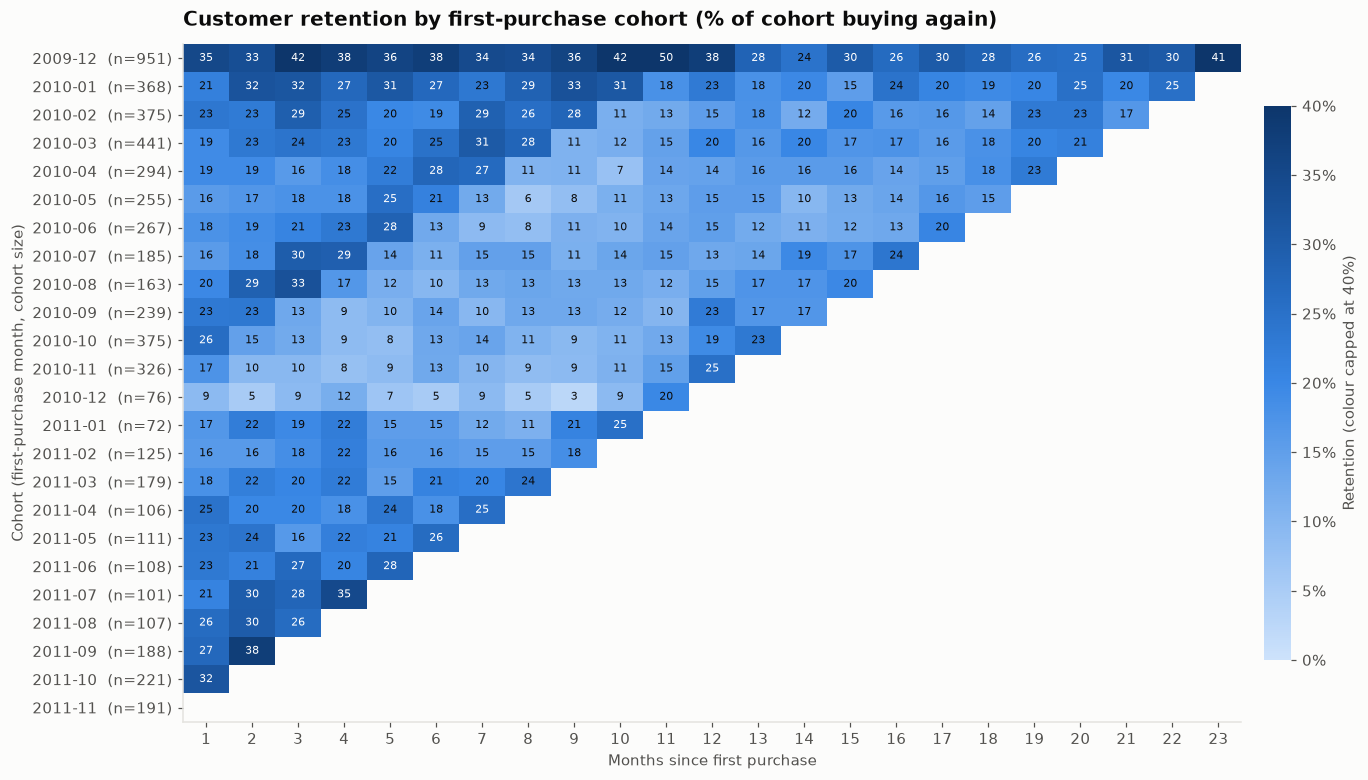

In [16]:
mat = retention.drop(columns=0)
cmap = LinearSegmentedColormap.from_list("blues", an.BLUES)
fig, ax = plt.subplots(figsize=(13, 8))
im = ax.imshow(mat.to_numpy(dtype=float), cmap=cmap, vmin=0, vmax=40, aspect="auto")
for (i, j), v in np.ndenumerate(mat.to_numpy(dtype=float)):
    if not np.isnan(v):
        ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=7,
                color="white" if v >= 25 else an.INK)
ax.set_xticks(range(mat.shape[1]), mat.columns)
ax.set_yticks(range(mat.shape[0]), [f"{c:%Y-%m}  (n={sizes[c]:,})" for c in mat.index])
ax.grid(False)
ax.set_title("Customer retention by first-purchase cohort (% of cohort buying again)")
ax.set_xlabel("Months since first purchase")
ax.set_ylabel("Cohort (first-purchase month, cohort size)")
cbar = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.02, format=PercentFormatter(decimals=0))
cbar.outline.set_visible(False)
cbar.set_label("Retention (colour capped at 40%)", color=an.INK_2)
saved.append(an.save_fig(fig, "06_cohort_retention_heatmap"))
plt.show()

## 5. RFM segmentation

- Snapshot date = last InvoiceDate + 1 day.
- **R** = days since the last purchase. **F** = distinct non-cancelled invoices. **M** = net revenue (purchases minus cancellations).
- Customers with M <= 0 are dropped.
- Each metric is scored 1-5 by quintiles, where 5 is best. For R, fewer days scores higher. F is ranked first so that ties split evenly across quintiles.

**Segment rules.** Rules are checked top to bottom and the first match wins, so every customer gets exactly one segment.

| # | Segment | Rule | Meaning |
|---|---|---|---|
| 1 | Champions | R >= 4, F >= 4, M >= 4 | Bought recently, often, and spend the most |
| 2 | Cannot Lose Them | R <= 2, F >= 4, M >= 4 | Used to be top customers, but have not bought for a long time |
| 3 | Loyal | R >= 3, F >= 4 | Buy often and fairly recently |
| 4 | At Risk | R <= 2, F >= 3 | Used to buy regularly, but have gone quiet |
| 5 | New | R >= 4, F = 1 | First and only purchase was recent |
| 6 | Potential Loyalists | R >= 4, F = 2 or 3 | Recent customers with a few orders |
| 7 | Hibernating | R = 3, F <= 3 | Few orders, last one a while ago |
| 8 | Lost | R <= 2, F <= 2 | Few orders, last one long ago |

In [17]:
rfm_raw, dropped, snapshot = an.rfm_table(cust)
rfm = an.score_rfm(rfm_raw)
print(f"Snapshot date: {snapshot:%Y-%m-%d}")
print(f"Customers scored: {len(rfm):,}. Dropped with M <= 0: {dropped:,}")
seg = an.segment_summary(rfm)
seg

Snapshot date: 2011-12-10
Customers scored: 5,838. Dropped with M <= 0: 37


,customers,customers_pct,revenue,revenue_pct,avg_recency_days,avg_frequency,avg_revenue_per_customer
segment,,,,,,,
Champions,1280,21.9,"11,327,072.2",69.2,19.2,17.1,"8,849.3"
Cannot Lose Them,233,4.0,"895,026.0",5.5,341.0,9.0,"3,841.3"
Loyal,697,11.9,"1,777,753.5",10.9,82.8,7.7,"2,550.6"
At Risk,591,10.1,"537,874.6",3.3,376.9,3.4,910.1
New,168,2.9,"53,958.3",0.3,28.8,1.0,321.2
Potential Loyalists,717,12.3,"629,723.0",3.8,25.3,2.6,878.3
Hibernating,646,11.1,"532,428.4",3.3,108.4,2.1,824.2
Lost,1506,25.8,"607,712.3",3.7,456.1,1.3,403.5


Top 20% of customers by net revenue make 76.7% of customer revenue


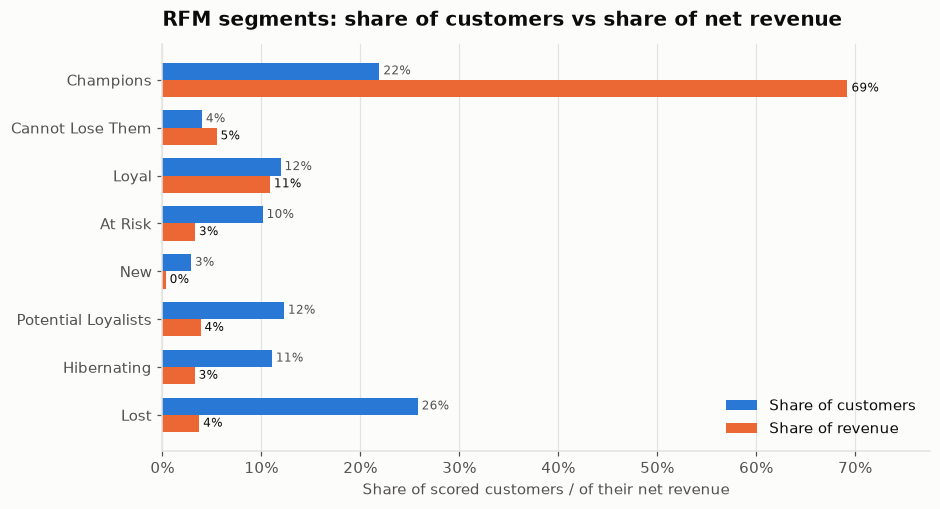

In [18]:
top20 = an.top_share(rfm["monetary"], 0.2)
print(f"Top 20% of customers by net revenue make {top20:.1f}% of customer revenue")
fig, ax = plt.subplots(figsize=(9, 4.8))
y = np.arange(len(seg))[::-1]
h = 0.36
ax.barh(y + h / 2, seg["customers_pct"], height=h, color=an.BLUE, label="Share of customers")
ax.barh(y - h / 2, seg["revenue_pct"], height=h, color=an.ORANGE, label="Share of revenue")
for yi, v in zip(y, seg["revenue_pct"]):
    ax.text(v, yi - h / 2, f" {v:.0f}%", va="center", fontsize=8, color=an.INK)
for yi, v in zip(y, seg["customers_pct"]):
    ax.text(v, yi + h / 2, f" {v:.0f}%", va="center", fontsize=8, color=an.INK_2)
ax.set_yticks(y, seg.index)
ax.xaxis.set_major_formatter(PercentFormatter())
ax.grid(axis="y", visible=False)
ax.set_xlim(0, seg[["customers_pct", "revenue_pct"]].max().max() * 1.12)
ax.set_title("RFM segments: share of customers vs share of net revenue")
ax.set_xlabel("Share of scored customers / of their net revenue")
ax.legend(loc="lower right")
saved.append(an.save_fig(fig, "07_rfm_segments"))
plt.show()

## 6. Customer lifetime value (simple, historical)

- **Historical LTV** = average net revenue per customer over the whole period (Dec 2009 to Dec 2011). It is a backward-looking average, not a forecast, and it ignores margin and discounting.
- **Cumulative revenue at 3, 6 and 12 months** = average net revenue per customer in their first k months, where the first-purchase month counts as month 1. Only cohorts whose k-th month is complete are used, so the 12-month figure only uses cohorts up to December 2010. Customers with no further purchases count as zero after their first month.

In [19]:
all_cust_rev = cust.groupby("Customer ID")["line_revenue"].sum()
ltv = pd.Series({
    "All customers (incl. M <= 0)": all_cust_rev.mean(),
    "RFM-scored customers (M > 0)": rfm["monetary"].mean(),
    "Median, RFM-scored customers": rfm["monetary"].median(),
}, name="historical_ltv_gbp")
display(ltv.to_frame())
seg[["customers", "avg_revenue_per_customer", "avg_frequency"]].rename(
    columns={"avg_revenue_per_customer": "historical_ltv_gbp"})

,historical_ltv_gbp
All customers (incl. M <= 0),"2,784.4"
RFM-scored customers (M > 0),"2,802.6"
"Median, RFM-scored customers",842.4


,customers,historical_ltv_gbp,avg_frequency
segment,,,
Champions,1280,"8,849.3",17.1
Cannot Lose Them,233,"3,841.3",9.0
Loyal,697,"2,550.6",7.7
At Risk,591,910.1,3.4
New,168,321.2,1.0
Potential Loyalists,717,878.3,2.6
Hibernating,646,824.2,2.1
Lost,1506,403.5,1.3


In [20]:
cum = pd.concat({
    "all cohorts": an.cumulative_ltv(cust),
    "excl. Dec 2009": an.cumulative_ltv(cust, exclude_cohorts=first_cohort),
})
cum

avg_cum_revenue  customers  cohorts last_cohort
               months                                                 
all cohorts    3                 766.1       5412       22     2011-09
               6               1,176.0       5016       19     2011-06
               12              2,119.7       4315       13     2010-12
excl. Dec 2009 3                 634.5       4461       21     2011-09
               6                 895.2       4065       18     2011-06
               12              1,373.0       3364       12     2010-12

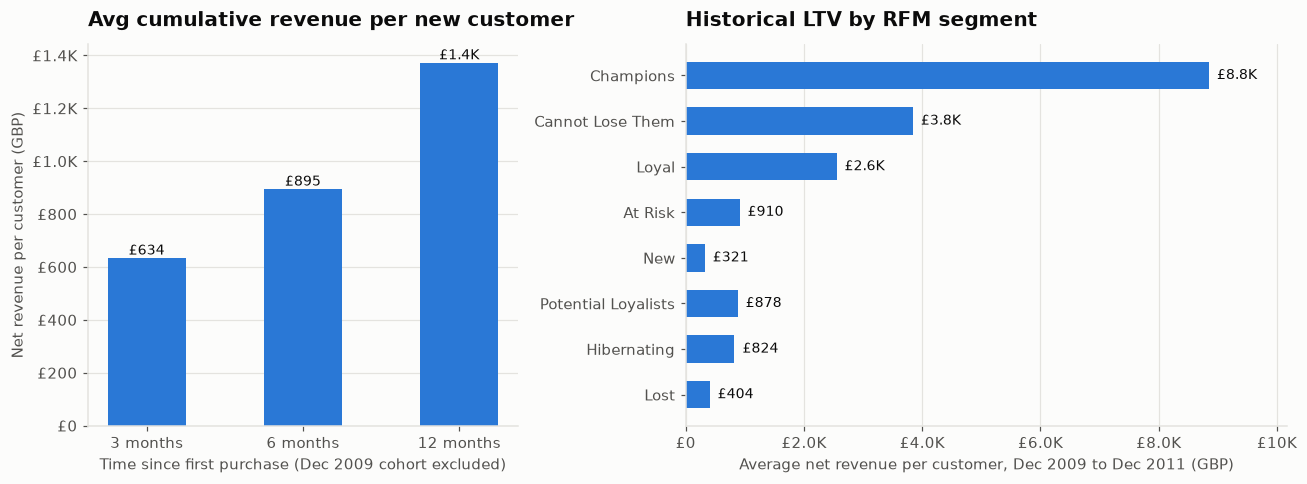

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), gridspec_kw={"width_ratios": [1, 1.4]})
c = cum.loc["excl. Dec 2009"]
axes[0].bar([f"{k} months" for k in c.index], c["avg_cum_revenue"], width=0.5, color=an.BLUE)
for i, v in enumerate(c["avg_cum_revenue"]):
    axes[0].text(i, v, an.gbp(v), ha="center", va="bottom", fontsize=9, color=an.INK)
axes[0].yaxis.set_major_formatter(an.GBP_FMT)
axes[0].grid(axis="x", visible=False)
axes[0].set_title("Avg cumulative revenue per new customer")
axes[0].set_xlabel("Time since first purchase (Dec 2009 cohort excluded)")
axes[0].set_ylabel("Net revenue per customer (GBP)")

s = seg["avg_revenue_per_customer"]
axes[1].barh(s.index[::-1], s[::-1], height=0.6, color=an.BLUE)
for i, v in enumerate(s[::-1]):
    axes[1].text(v, i, f"  {an.gbp(v)}", va="center", fontsize=9, color=an.INK)
axes[1].xaxis.set_major_formatter(an.GBP_FMT)
axes[1].grid(axis="y", visible=False)
axes[1].set_xlim(0, s.max() * 1.15)
axes[1].set_title("Historical LTV by RFM segment")
axes[1].set_xlabel("Average net revenue per customer, Dec 2009 to Dec 2011 (GBP)")
fig.tight_layout()
saved.append(an.save_fig(fig, "08_ltv"))
plt.show()

## 7. Exports for Power BI

CSV files in `data/processed/powerbi/` (UTF-8, ISO dates). `fact_sales` holds product rows only, matching every number in this notebook. It has one extra column, `is_fully_cancelled_order`, so the Orders and AOV measures in Power BI can exclude fully cancelled orders.
`monthly_kpis` includes December 2011 with `is_partial_month = True` so it can be filtered out of trend visuals.

In [22]:
fact_sales = df.rename(columns={"InvoiceDate": "date", "Invoice": "invoice", "StockCode": "stock_code",
                                "Description": "description", "Country": "country", "Customer ID": "customer_id",
                                "Quantity": "quantity", "Price": "price"})[
    ["date", "invoice", "stock_code", "description", "country", "customer_id",
     "quantity", "price", "line_revenue", "is_cancelled", "has_customer"]].assign(
    is_fully_cancelled_order=df["Invoice"].isin(fully_cancelled))
cohort_long = (retention.stack().rename("retention_pct").reset_index()
               .rename(columns={"cohort": "cohort", "month_index": "month_index"}))
cohort_long["cohort_size"] = cohort_long["cohort"].map(sizes)
rfm_out = rfm.reset_index().rename(columns={"Customer ID": "customer_id", "R": "R_score", "F": "F_score",
                                            "M": "M_score", "monetary": "net_revenue"})
exports = {
    "fact_sales": fact_sales,
    "monthly_kpis": monthly,
    "cohort_retention": cohort_long,
    "rfm_customers": rfm_out,
    "segment_summary": seg.reset_index(),
}
for name, table in exports.items():
    p = an.to_csv(table, name)
    saved.append(p)
    print(f"{p.relative_to(ROOT)}: {len(table):,} rows")

E:\BI\mini\online-retail-analysis\src\analysis.py:333: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  out = out.round(4)


data\processed\powerbi\fact_sales.csv: 1,021,272 rows
data\processed\powerbi\monthly_kpis.csv: 25 rows
data\processed\powerbi\cohort_retention.csv: 576 rows
data\processed\powerbi\rfm_customers.csv: 5,838 rows
data\processed\powerbi\segment_summary.csv: 8 rows


In [23]:
print("Saved files:")
for p in saved:
    print(" -", p.relative_to(ROOT))

Saved files:
 - reports\tables\kpis.csv
 - reports\figures\01_monthly_net_revenue.png
 - reports\figures\02_revenue_2010_vs_2011.png
 - reports\figures\03_top_countries_excl_uk.png
 - reports\figures\04_top_products.png
 - reports\figures\05_pareto_products.png
 - reports\tables\cohort_retention_matrix.csv
 - reports\figures\06_cohort_retention_heatmap.png
 - reports\figures\07_rfm_segments.png
 - reports\figures\08_ltv.png
 - data\processed\powerbi\fact_sales.csv
 - data\processed\powerbi\monthly_kpis.csv
 - data\processed\powerbi\cohort_retention.csv
 - data\processed\powerbi\rfm_customers.csv
 - data\processed\powerbi\segment_summary.csv


## Key findings

All figures are for products only, in GBP. "Like-for-like" compares January to November of 2010 and 2011.

**1. Revenue is flat. Bigger orders offset fewer orders.**
Like-for-like net revenue grew **+2.3%**, from £8.38M to £8.57M. Orders fell **3.6%**, from 17,940 to 17,294, and customers grew only **1.0%**. Average order value rose **+5.5%**, from **£475 to £501**. These figures exclude 250 orders in the period that were fully cancelled, including the two bulk orders.
*Implication:* growth is coming from basket size, not from more orders. Order frequency and new-customer acquisition are the untapped levers.

**2. The business is highly seasonal and peaks in November.**
September to November make up **41%** of January-November net revenue in 2011, and 40% in 2010. November is the peak month in both years, at **£1.43M** in 2011, about **3 times** April 2011 (£482K).
*Implication:* stock, staffing and marketing for the Q4 peak have to be in place by August. Cash-flow planning should expect a weak January to April.

**3. Revenue is concentrated in few customers, few products and one country.**
The top **20% of customers make 77%** of customer revenue. Champions are **22%** of customers and bring **69%** of revenue. **22% of the 4,739 products make 80%** of product revenue, and the **UK accounts for 85%**.
*Implication:* key-account care for top customers matters more than broad campaigns. The "Cannot Lose Them" segment is **233 customers** worth **£895K** historically, who have not bought for about **11 months** on average. They are the clearest win-back target.

**4. Most new customers do not come back.**
On average only **21%** of a cohort buys again in month 1, and **21%** in month 3, excluding the December 2009 cohort. A new customer brings **£634** in their first 3 months and **£1,373** in their first 12, so repeat purchases more than double first-year value. The December 2010 cohort of Christmas buyers retained worst, at **9%** in month 1.
*Implication:* a second-purchase program, such as a follow-up offer within 30 days, has a large payoff. Track month-1 retention as a core KPI.

**5. The 2011 cancellation spike is two bulk orders, not a trend.**
The headline cancellation rate doubled from **2.5%** in 2010 to **4.8%** in 2011. Two bulk orders of 80,995 and 74,215 units, cancelled within minutes, account for **about £245K** of the 2011 cancellations. Without them the 2011 rate is **2.3%**, in line with 2010.
*Implication:* KPI reporting should flag or exclude one-off bulk orders so that they do not distort revenue and cancellation trends. Very large orders should get a manual check before they are booked.